In [90]:
import sys
print(sys.version)


3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:11:32) [Clang 20.1.8 ]


In [91]:
pip install jieba


Note: you may need to restart the kernel to use updated packages.


In [92]:
import jieba
import jieba.posseg as pseg

sents = ["加强高标准农田建设，提升耕地质量","推动数字乡村和智慧农业发展"]

for s in sents:
    print("精确模式:",jieba.lcut(s))
    print("全模式:",jieba.lcut(s,cut_all=True))
    print("搜索模式:",jieba.lcut_for_search(s))


精确模式: ['加强', '高标准', '农田', '建设', '，', '提升', '耕地', '质量']
全模式: ['加强', '高标', '高标准', '标准', '农田', '建设', '，', '提升', '耕地', '地质', '质量']
搜索模式: ['加强', '高标', '标准', '高标准', '农田', '建设', '，', '提升', '耕地', '质量']
精确模式: ['推动', '数字', '乡村', '和', '智慧', '农业', '发展']
全模式: ['推动', '数字', '乡村', '和', '智慧', '农业', '发展']
搜索模式: ['推动', '数字', '乡村', '和', '智慧', '农业', '发展']


In [93]:
stopwords_path = "/Users/fengqiukai/Downloads/data/case3/stopwords.txt"
stop = set(open(stopwords_path,encoding="utf-8").read().split())
words = [w for s in sents for w in jieba.lcut(s) if w not in stop and len(w) >1]
print(words)

['加强', '高标准', '农田', '建设', '提升', '耕地', '质量', '推动', '数字', '乡村', '智慧', '农业', '发展']


In [94]:
for s in sents:
 print([(p.word,p.flag)for p in pseg.cut(s) if p.flag[0] in "nv"])

[('加强', 'v'), ('高标准', 'n'), ('农田', 'n'), ('建设', 'vn'), ('提升', 'v'), ('耕地', 'n'), ('质量', 'n')]
[('推动', 'v'), ('数字', 'n'), ('乡村', 'n'), ('智慧', 'nr'), ('农业', 'n'), ('发展', 'vn')]


In [95]:
%pip install thulac


Note: you may need to restart the kernel to use updated packages.


In [96]:
import jieba
import thulac as thu

gold_path = "/Users/fengqiukai/Downloads/data/case3/gold_exp.txt"

gold = [l.split() for l in open(gold_path, encoding="utf-8") if l.strip()]
sents = ["".join(g) for g in gold]

print(sents)


pred_jieba = [jieba.lcut(s) for s in sents]

thu = thulac.thulac(seg_only=True)
pred_thu = [[w for w, _ in thu.cut(s)] for s in sents]

print(pred_jieba)
print(pred_thu)


def spans(words):
    res, i = set(), 0
    for w in words:
        res.add((i, i + len(w)))
        i += len(w)
    return res


def prf(pred_list, gold_list):
    hit = p_n = g_n = 0

    for p, g in zip(pred_list, gold_list):
        sp, sg = spans(p), spans(g)
        hit += len(sp & sg)
        p_n += len(sp)
        g_n += len(sg)

    P = hit / p_n if p_n else 0
    R = hit / g_n if g_n else 0
    F1 = 2 * P * R / (P + R) if P + R else 0

    return round(P, 3), round(R, 3), round(F1, 3)


print("jieba :", prf(pred_jieba, gold))
print("thulac:", prf(pred_thu, gold))

['各银行信用卡挂失费迥异北京银行收费最高', '海淀专家国际公馆60平米公寓均价24000元', '保诚启动210亿美元配股交易以融资收购AIG部门', '中华女子学院：本科层次仅1专业招男生', '“手机钱包”亮相科博会', '90岁老太半世纪撮合200多对新人', '民政部长称明年将提高特殊群体供养水平', '中信银行业巡赛南京站球员关注赛事', '《赤壁OL》攻城战诸侯战硝烟又起', '赵本山要追究法律责任：居然诽谤我打小沈阳']
Model loaded succeed
[['各', '银行', '信用卡', '挂失', '费', '迥异', '北京', '银行', '收费', '最高'], ['海淀', '专家', '国际', '公馆', '60', '平米', '公寓', '均价', '24000', '元'], ['保诚', '启动', '210', '亿美元', '配股', '交易', '以', '融资', '收购', 'AIG', '部门'], ['中华', '女子', '学院', '：', '本科', '层次', '仅', '1', '专业', '招', '男生'], ['“', '手机', '钱包', '”', '亮相', '科博会'], ['90', '岁', '老太', '半世纪', '撮合', '200', '多', '对', '新人'], ['民政', '部长', '称', '明年', '将', '提高', '特殊', '群体', '供养', '水平'], ['中信银行', '业', '巡赛', '南京站', '球员', '关注', '赛事'], ['《', '赤壁', 'OL', '》', '攻城战', '诸侯', '战', '硝烟', '又', '起'], ['赵本山', '要', '追究', '法律责任', '：', '居然', '诽谤', '我', '打', '小', '沈阳']]
[['各', '银行', '信用卡', '挂失费', '迥异', '北京', '银行', '收费', '最高'], ['海淀', '专', '家', '国际', '公馆', '60', '平米', '公寓', '均', '价', '24000', '元'], ['保诚', '启动', '210亿', '美元', '配股', '交易', '以', '

In [97]:
for s, a, b in zip(sents,pred_jieba,pred_thu):
    if a !=b:
        print(s,"\n jieba :","/".join(a),"\n rhulac:","/".join(b))
              

各银行信用卡挂失费迥异北京银行收费最高 
 jieba : 各/银行/信用卡/挂失/费/迥异/北京/银行/收费/最高 
 rhulac: 各/银行/信用卡/挂失费/迥异/北京/银行/收费/最高
海淀专家国际公馆60平米公寓均价24000元 
 jieba : 海淀/专家/国际/公馆/60/平米/公寓/均价/24000/元 
 rhulac: 海淀/专/家/国际/公馆/60/平米/公寓/均/价/24000/元
保诚启动210亿美元配股交易以融资收购AIG部门 
 jieba : 保诚/启动/210/亿美元/配股/交易/以/融资/收购/AIG/部门 
 rhulac: 保诚/启动/210亿/美元/配股/交易/以/融资/收购/AIG部门
中华女子学院：本科层次仅1专业招男生 
 jieba : 中华/女子/学院/：/本科/层次/仅/1/专业/招/男生 
 rhulac: 中华/女子/学院/：/本科/层次/仅/1/专业/招男生
90岁老太半世纪撮合200多对新人 
 jieba : 90/岁/老太/半世纪/撮合/200/多/对/新人 
 rhulac: 90/岁/老太半/世纪/撮合/200/多/对/新人
民政部长称明年将提高特殊群体供养水平 
 jieba : 民政/部长/称/明年/将/提高/特殊/群体/供养/水平 
 rhulac: 民政部长/称明年/将/提高/特殊/群体/供养/水平
中信银行业巡赛南京站球员关注赛事 
 jieba : 中信银行/业/巡赛/南京站/球员/关注/赛事 
 rhulac: 中信/银行业/巡赛/南京/站/球员/关注/赛事
《赤壁OL》攻城战诸侯战硝烟又起 
 jieba : 《/赤壁/OL/》/攻城战/诸侯/战/硝烟/又/起 
 rhulac: 《/赤壁OL/》/攻/城战/诸侯战/硝烟/又/起
赵本山要追究法律责任：居然诽谤我打小沈阳 
 jieba : 赵本山/要/追究/法律责任/：/居然/诽谤/我/打/小/沈阳 
 rhulac: 赵本山/要/追究/法律/责任/：/居然/诽谤/我/打/小/沈阳


In [98]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [99]:
import pandas as pd
import jieba
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

In [100]:
import pandas as pd
import jieba
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

plt.rcParams["font.sans-serif"] = ["PingFang SC"]
plt.rcParams["axes.unicode_minus"] = False

gov_path = "/Users/fengqiukai/Downloads/data/case3/2026_政府工作报告.txt"
stopwords_path = "/Users/fengqiukai/Downloads/data/case3/stopwords.txt"

with open(gov_path, "r", encoding="utf-8") as f:
    text = f.read()

with open(stopwords_path, "r", encoding="utf-8") as f:
    stop = set(f.read().split())

words = [
    w for w in jieba.lcut(text)
    if len(w) > 1
    and w not in stop
    and not any(c.isdigit() for c in w)
]

print(words)

['国务院', '政府', '工作', '报告', '全文', '来源', '中国政府', 'https', 'www', 'gov', 'cn', 'yaowen', 'liebiao', 'content', 'htm', '新华社', '北京', '日电', '政府', '工作', '报告', '第十四届', '全国人民代表大会', '第四次', '会议', '国务院', '总理', '李强', '李强', '总理', '代表', '国务院', '十四届', '全国人大', '四次会议', '上作', '政府', '工作', '报告', '新华社', '记者', '黄敬文', '代表', '现在', '代表', '国务院', '大会', '政府', '工作', '报告', '请予', '审议', '全国政协', '委员', '提出', '意见', '工作', '回顾', '平凡', '一年', '二十', '四中全会', '胜利', '召开', '擘画', '未来', '五年', '我国', '发展', '宏伟蓝图', '隆重', '纪念', '中国', '人民', '抗日战争', '世界反法西斯战争', '胜利', '周年', '设立', '台湾光复', '纪念日', '极大', '振奋', '民族', '精神', '激发', '爱国热情', '凝聚', '奋斗', '力量', '面对', '国内外', '形势', '深刻', '复杂', '变化', '习近平', '同志', '核心', '党中央', '团结', '带领', '全国', '各族人民', '迎难而上', '奋力拼搏', '坚定不移', '贯彻', '发展', '理念', '推动', '高质量', '发展', '统筹', '国内', '国际', '两个', '大局', '全年', '经济社会', '发展', '主要', '目标', '任务', '顺利完成', '十四五', '圆满', '收官', '中国式', '现代化', '迈出', '坚实', '步伐', '一年', '我国', '经济', '顶压', '前行', '展现', '强大', '韧性', '经济运行', '总体', '平稳', '稳中有进', '国内', '生产总值', '增长', '总量', '达到', '万亿元', '就业',

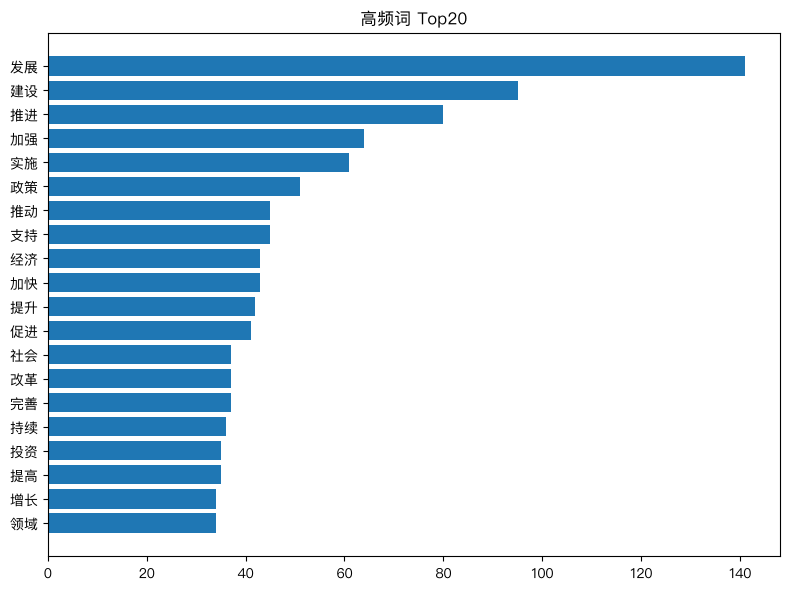

In [102]:

freq = Counter(words)
top = freq.most_common(20)

plt.figure(figsize=(8, 6))
plt.barh([w for w, _ in top][::-1],
         [n for _, n in top][::-1])

plt.title("高频词 Top20")
plt.tight_layout()
plt.savefig("top20.png", dpi=150)
plt.show()

In [104]:
import os

for folder in ["/System/Library/Fonts", "/Library/Fonts"]:
    for root, dirs, files in os.walk(folder):
        for f in files:
            if any(x in f.lower() for x in ["pingfang", "heiti", "simhei", "songti"]):
                print(os.path.join(root, f))

                

/System/Library/Fonts/STHeiti Medium.ttc
/System/Library/Fonts/STHeiti Light.ttc
/System/Library/Fonts/Supplemental/Songti.ttc


from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(
    font_path="/System/Library/Fonts/STHeiti Medium.ttc",
    background_color="white",
    width=900,
    height=600
)

wc.generate_from_frequencies(freq)

wc.to_file("/Users/fengqiukai/Downloads/wordcloud.png")

plt.figure(figsize=(10, 6))
plt.imshow(wc)
plt.axis("off")
plt.show()

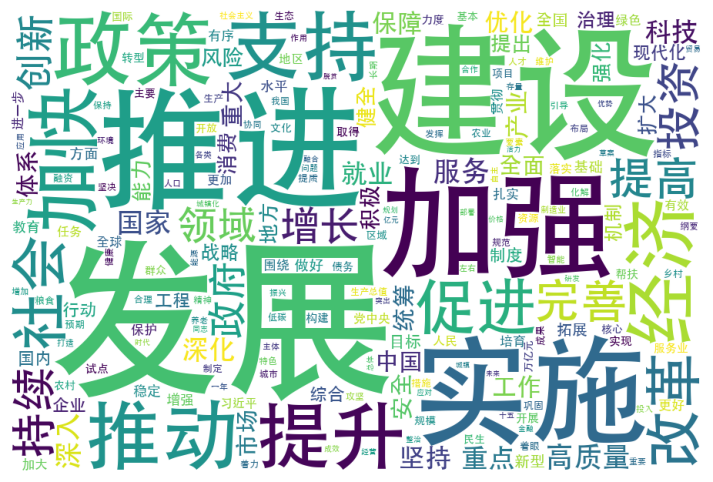

In [105]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(
    font_path="/System/Library/Fonts/STHeiti Medium.ttc",
    background_color="white",
    width=900,
    height=600
)

wc.generate_from_frequencies(freq)

wc.to_file("/Users/fengqiukai/Downloads/wordcloud.png")

plt.figure(figsize=(10, 6))
plt.imshow(wc)
plt.axis("off")
plt.show()